# 01 · Datos y calidad
**Proyecto Integrador ML2 — Segunda entrega · Predicción de la TRM**

**Objetivo de este notebook (rúbrica 7.1, consolidación de los datos).** Verificar que la copia congelada de los datos es la que se descargó, leer las cinco series, recortarlas al periodo de estudio de la Entrega 1 (diciembre de 2003 a la fecha de descarga), medir su calidad y dejar las series limpias para el notebook 02.

**De dónde vienen los datos.** `scripts/descargar_datos.py` los bajó de las fuentes oficiales por API y los guardó sin modificar en `data/raw/`, con su huella MD5 en `metadatos.json`. Este notebook no descarga nada: trabaja sobre esa copia, porque las fuentes corrigen datos históricos y una descarga nueva podría cambiar los resultados.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import config as cfg
from src.descarga import FUENTES, leer, md5
from src.calidad import recortar_periodo, cambios_extremos, tabla_calidad
from src.graficos import estilo, guardar_figura, guardar_tabla, COLORES

estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
INICIO, FIN = cfg.FECHA_INICIO, cfg.exigir_fecha_fin()
print(f"Periodo de estudio: {INICIO} a {FIN} | semilla {cfg.SEMILLA}")

Periodo de estudio: 2003-12-01 a 2026-09-29 | semilla 42


## 1. ¿La copia congelada es la que se descargó?
Se recalcula el MD5 de cada archivo crudo y se compara con el registrado al descargarlo. Si alguien editó un archivo, el notebook se detiene aquí.

In [2]:
meta = json.loads((cfg.DATA_RAW / "metadatos.json").read_text(encoding="utf-8"))
for nombre, info in FUENTES.items():
    assert md5(cfg.DATA_RAW / info["archivo"]) == meta[nombre]["md5"], f"{nombre}: el archivo no coincide con su MD5"

fuentes = pd.DataFrame(meta).T[["fuente", "descargado_utc", "filas", "fecha_min", "fecha_max", "md5"]]
guardar_tabla(fuentes, "tab00_fuentes")
print("Los 6 archivos crudos coinciden con su huella MD5.")
display(fuentes)

Los 6 archivos crudos coinciden con su huella MD5.


,fuente,descargado_utc,filas,fecha_min,fecha_max,md5
trm,"TRM diaria (COP por USD), Banco de la Repúblic...",2026-09-30T01:17:18+00:00,8674,2003-01-01,2026-09-30,eff5741000b4277d8b42ae1fcd09a43b
trm_vigencias,TRM con fechas de vigencia (una fila por TRM p...,2026-09-30T01:17:19+00:00,5633,2003-01-03,2026-09-30,cf29a1dceb83b234681365072962b425
tpm,"Tasa de política monetaria vigente al día (%),...",2026-09-30T01:17:29+00:00,8673,2003-01-01,2026-09-29,d0381fe72f6171096572afa61035bd80
brent,"Petróleo Brent, USD por barril, FRED serie DCO...",2026-09-30T01:17:29+00:00,10265,1987-05-20,2026-09-22,9900f9d3a6c66c240563cf31a5df909b
dff,"Tasa efectiva de fondos federales (%), FRED se...",2026-09-30T01:17:29+00:00,26388,1954-07-01,2026-09-28,e14578b638b691963eecb0f0d5d20508
dxy,"Índice del dólar (DXY), cierre diario, Yahoo F...",2026-09-30T01:17:30+00:00,5988,2003-01-02,2026-09-29,0148016862e8b168bb888a35df3d121a


## 2. Lectura, recorte al periodo y verificación cruzada de la TRM
La TRM se descargó de dos fuentes oficiales:
- **Banco de la República** (servicio web SDMX): un valor por cada día calendario. Es la fuente de la Entrega 1.
- **Superintendencia Financiera en datos.gov.co:** una fila por **TRM publicada**, con su vigencia (desde–hasta). Una TRM calculada un viernes rige sábado, domingo y el lunes festivo.

Se usa la segunda para tener **una fila por TRM publicada**, que es la unidad de la predicción, y se verifica que sus valores coinciden con los del Banrep en cada día.

In [3]:
crudas = {n: recortar_periodo(leer(n), INICIO, FIN) for n in ["trm", "trm_vigencias", "brent", "dff", "dxy", "tpm"]}

# Verificación cruzada: expandir cada vigencia a sus días y comparar con la serie diaria del Banrep
vig = crudas["trm_vigencias"]
dias = pd.DataFrame([(d, r.valor) for r in vig.itertuples()
                     for d in pd.date_range(r.fecha, min(r.vigencia_hasta, pd.Timestamp(FIN)))],
                    columns=["fecha", "valor_vigencias"])
cruce = crudas["trm"].merge(dias, on="fecha", how="inner")
dif = (cruce["valor"] - cruce["valor_vigencias"]).abs()
assert dif.max() < 0.005, "La TRM del Banrep y la de datos.gov.co no coinciden"
assert vig["fecha"].is_monotonic_increasing and not vig["fecha"].duplicated().any()
assert (vig["vigencia_hasta"] >= vig["fecha"]).all()
print(f"TRM: {len(cruce):,} días comparados entre Banrep y datos.gov.co; diferencia máxima {dif.max():.2f} pesos.")
print(f"TRM publicadas en el periodo: {len(vig):,} (de {vig['fecha'].min().date()} a {vig['fecha'].max().date()})")

TRM: 8,338 días comparados entre Banrep y datos.gov.co; diferencia máxima 0.00 pesos.
TRM publicadas en el periodo: 5,412 (de 2003-12-02 a 2026-09-29)


## 3. Tabla de calidad por serie
Para cada serie, dentro del periodo:
- **Observaciones y faltantes.** En FRED, un día sin dato aparece como "." (festivos en EE. UU. o Europa): se cuenta como faltante y **no se rellena aquí**; el relleno se decide en la alineación (notebook 02), sin mirar el futuro.
- **Fechas duplicadas** y **valores fuera de un rango plausible**: deben ser cero.
- **Mayor hueco:** el mayor salto entre dos fechas con dato, en días.
- **Cambios extremos:** en precios (TRM, Brent, DXY), retornos diarios de más de 5 desviaciones estándar; en tasas, movimientos de más de 1 punto porcentual en un día en la TPM y de más de 0,5 en la DFF. **No se eliminan:** son eventos reales (crisis, pandemia, decisiones de política) y se documentan para interpretar los errores.

In [4]:
series = {
    "TRM": crudas["trm_vigencias"][["fecha", "valor"]],   # una fila por TRM publicada
    "Brent": crudas["brent"],
    "DFF": crudas["dff"],
    "DXY": crudas["dxy"],
    "TPM": crudas["tpm"],
}
rangos = {"TRM": (1_000, 7_000), "Brent": (5, 200), "DFF": (0, 20), "DXY": (60, 130), "TPM": (0, 20)}
extremos = {
    "TRM": cambios_extremos(series["TRM"]),
    "Brent": cambios_extremos(series["Brent"]),
    "DXY": cambios_extremos(series["DXY"]),
    "DFF": cambios_extremos(series["DFF"], en_niveles=True, umbral_abs=0.5),
    "TPM": cambios_extremos(series["TPM"], en_niveles=True, umbral_abs=1.0),
}
calidad = tabla_calidad(series, rangos, extremos)
assert (calidad["fechas_duplicadas"] == 0).all() and (calidad["fuera_de_rango"] == 0).all()
guardar_tabla(calidad, "tab01_calidad")
display(calidad)

,desde,hasta,observaciones,faltantes,fechas_duplicadas,minimo,maximo,fuera_de_rango,mayor_hueco_dias,cambios_extremos
serie,,,,,,,,,,
TRM,2003-12-02,2026-09-29,5412,0,0,"1,652.4100","5,061.2100",0,6,10
Brent,2003-12-01,2026-09-22,5684,268,0,9.1200,143.9500,0,9,15
DFF,2003-12-01,2026-09-28,8338,0,0,0.0400,5.4100,0,1,20
DXY,2003-12-01,2026-09-29,5756,0,0,71.3300,114.1100,0,5,4
TPM,2003-12-01,2026-09-29,8339,0,0,1.7500,13.2500,0,1,2


In [5]:
# Los cambios extremos, uno por uno, para explicarlos (los 5 más grandes por serie)
for nombre, ext in extremos.items():
    top = ext.reindex(ext["cambio"].abs().sort_values(ascending=False).index).head(5)
    print(f"\n{nombre}: {len(ext)} cambios extremos")
    display(top.assign(fecha=top["fecha"].dt.date).reset_index(drop=True))

# Mayor hueco de cada serie: cuándo ocurrió
for nombre, df in series.items():
    v = df.dropna(subset=["valor"]).reset_index(drop=True)
    i = v["fecha"].diff().dt.days.idxmax()
    print(f"{nombre}: mayor hueco de {int(v['fecha'].diff().dt.days.max())} días, "
          f"del {v.loc[i - 1, 'fecha'].date()} al {v.loc[i, 'fecha'].date()}")


TRM: 10 cambios extremos


,fecha,valor,cambio
0,2020-03-10,"3,803.6000",0.0593
1,2008-09-20,"2,067.4500",-0.0562
2,2008-07-03,"1,818.6000",-0.0519
3,2020-03-13,"4,034.6600",0.0507
4,2008-06-28,"1,923.0200",0.0480



Brent: 15 cambios extremos


,fecha,valor,cambio
0,2020-04-21,9.1200,-0.6437
1,2020-04-22,13.7700,0.4120
2,2020-04-02,20.2400,0.3016
3,2020-03-31,14.8500,-0.2564
4,2020-03-09,35.3300,-0.2552



DXY: 4 cambios extremos


...


DFF: 20 cambios extremos


,fecha,valor,cambio
0,2008-01-02,4.1100,1.0500
1,2008-10-07,2.9700,1.0100
2,2007-12-31,3.0600,-0.9500
3,2008-10-01,1.1500,-0.8800
4,2008-10-06,1.9600,0.8600



TPM: 2 cambios extremos


,fecha,valor,cambio
0,2022-07-01,7.5000,1.5000
1,2022-08-01,9.0000,1.5000


TRM: mayor hueco de 6 días, del 2008-03-20 al 2008-03-26
Brent: mayor hueco de 9 días, del 2005-03-08 al 2005-03-17
DFF: mayor hueco de 1 días, del 2003-12-01 al 2003-12-02
DXY: mayor hueco de 5 días, del 2012-10-26 al 2012-10-31
TPM: mayor hueco de 1 días, del 2003-12-01 al 2003-12-02


**Lectura de la tabla:**
- **Las cinco series están completas y son consistentes:** cero fechas duplicadas y cero valores fuera de rango. La TRM del Banrep y la de datos.gov.co coinciden al peso en los 8.338 días comparados.
- **TRM: 5.412 TRM publicadas**, entre 1.652 (2008) y 5.061 (noviembre de 2022). El hueco de 6 días es la Semana Santa de 2008. Sus 10 cambios extremos caen en episodios reales: la crisis de 2008 (junio a septiembre) y el inicio de la pandemia (10 y 13 de marzo de 2020, con subidas de 6 % y 5 % en un día).
- **Brent: 268 faltantes**, todos días sin cotización en Londres o Nueva York (festivos). El hueco de 9 días (del 8 al 17 de marzo de 2005) es un vacío de la serie publicada por FRED. Sus 15 extremos se concentran en el colapso de abril de 2020 (9,12 USD el 21 de abril, −64 % en un día). La serie termina el 22 de septiembre por el rezago de publicación de FRED.
- **DXY:** 4 extremos, todos entre 2008 y 2015. El hueco de 5 días es el cierre de los mercados por el huracán Sandy (octubre de 2012).
- **DFF:** 20 extremos, que son el ruido diario de la tasa antes y durante 2008 y los recortes de emergencia de la Fed.
- **TPM:** 2 extremos, las subidas de 150 pb de julio y agosto de 2022. Solo cambia en las reuniones de la Junta, así que día a día es constante.
- **Ningún extremo se elimina:** son eventos reales, y los modelos deben enfrentarlos. Quedan documentados para interpretar los errores.

## 4. Figura 1: las cinco series del proyecto

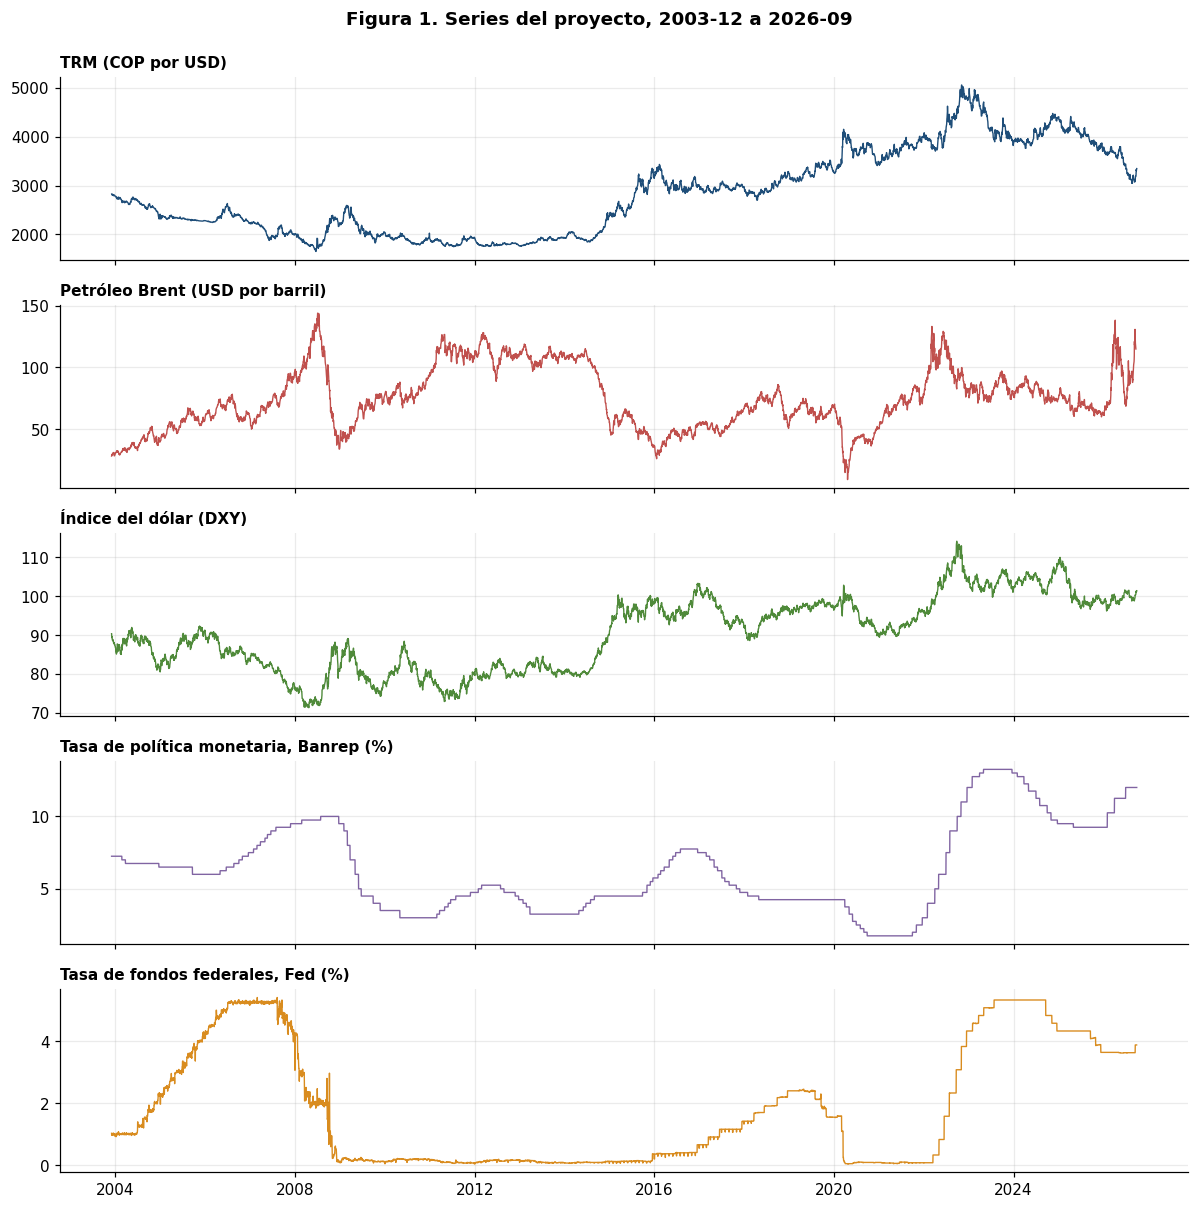

In [6]:
fig, ejes = plt.subplots(5, 1, figsize=(11, 11), sharex=True)
titulos = {"TRM": "TRM (COP por USD)", "Brent": "Petróleo Brent (USD por barril)", "DXY": "Índice del dólar (DXY)",
           "TPM": "Tasa de política monetaria, Banrep (%)", "DFF": "Tasa de fondos federales, Fed (%)"}
for eje, (nombre, color) in zip(ejes, zip(["TRM", "Brent", "DXY", "TPM", "DFF"], COLORES)):
    v = series[nombre].dropna(subset=["valor"])
    eje.plot(v["fecha"], v["valor"], color=color, lw=0.9)
    eje.set_title(titulos[nombre], loc="left", fontsize=10)
fig.suptitle(f"Figura 1. Series del proyecto, {INICIO[:7]} a {FIN[:7]}", fontweight="bold", y=0.995)
fig.tight_layout()
guardar_figura(fig, "fig01_series")
plt.show()

## 5. Series limpias para el notebook 02
Reglas aplicadas, y ninguna otra:
1. Recorte al periodo de estudio.
2. Se quitan las fechas sin valor (los "." de FRED). **No se interpola ni se rellena**: rellenar aquí con el dato siguiente sería usar el futuro. El relleno hacia atrás se hace en la alineación.
3. La TRM queda con **una fila por TRM publicada** y su fecha de fin de vigencia.

In [7]:
limpias = pd.concat([df.dropna(subset=["valor"]).assign(serie=n)[["serie", "fecha", "valor"]]
                     for n, df in series.items()], ignore_index=True)
limpias = limpias.merge(crudas["trm_vigencias"][["fecha", "vigencia_hasta"]].assign(serie="TRM"),
                        on=["serie", "fecha"], how="left")
assert limpias["valor"].notna().all()
limpias.to_csv(cfg.DATA_PROC / "series_limpias.csv", index=False)
display(limpias.groupby("serie").agg(filas=("valor", "size"), desde=("fecha", "min"), hasta=("fecha", "max")))
print("Guardado: data/processed/series_limpias.csv")

,filas,desde,hasta
serie,,,
Brent,5684,2003-12-01,2026-09-22
DFF,8338,2003-12-01,2026-09-28
DXY,5756,2003-12-01,2026-09-29
TPM,8339,2003-12-01,2026-09-29
TRM,5412,2003-12-02,2026-09-29


Guardado: data/processed/series_limpias.csv


## Qué llevar al informe
- **Tabla 1** (`reports/tablas/tab01_calidad.csv`): calidad por serie, con la lectura de arriba.
- **Figura 1** (`reports/figuras/fig01_series.png`): se ve que la TRM de 2022 (5.061) supera todo lo anterior. Ese es el argumento visual para no predecir el nivel con árboles (notebook 04).
- **Fuentes y congelamiento** (`reports/tablas/tab00_fuentes.csv`): las cinco series salen de fuentes oficiales por API; la copia se congela con huella MD5 porque FRED y Yahoo revisan datos históricos.
- **Verificación cruzada de la TRM:** Banrep y Superfinanciera coinciden al peso; se usa una fila por TRM publicada.
- **Tratamiento de faltantes:** aquí no se rellena nada; el relleno con el último dato conocido se hace en la alineación, sin mirar el futuro.